# Fig. 4a-b: Feedback decoding and neural value in the composite session

[AI generated summary] All units are pooled into a composite session (20 trials for each history of the last three outcomes, for each unit). A feedback decoder is trained at each time point (10-fold cross-validation):
- **Fig. 4a**: feedback decoding accuracy over time in MCC, dLPFC and vLPFC.
- **Fig. 4b**: population activity projected to the decision vector subspace (DVS) of the feedback decoder, averaged by the history of the last three outcomes (neural value; MCC is shown in the paper).

**How to run:** first build the composite session: `python run_build_composite_session.py meta_rates_history` in this folder (several hours; saved in `results/composite_sessions/`, it is not shared). The trials of the composite session are sampled randomly, so the results differ slightly from those of the paper. Then run all cells. Figures are saved in `figs/`.

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
from helpers_neural_value import *
from helpers import load_mega_custom
from popy.config import COLORS

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Fig. 4a, Feedback decoding

In [3]:
neural_dataset_all = load_mega_custom(downsample=True)

# create a new figure: the accuracies across areas

decodabilities = {}
for subregion in np.unique(neural_dataset_all.subregion.values):
    neural_dataset_subregion = neural_dataset_all.sel(unit=neural_dataset_all.subregion==subregion)
    ## 1. plot monkey average
    #results, weights, data_projected, pvalue = time_resolved_decoder(neural_dataset, target='R_1', t_project=t_interest_fit)
    decodability_matrix, data_projected = time_resolved_decoder_all_time(neural_dataset_subregion, target='R_1', across_time=False)

    decodabilities[str(subregion)] = data_projected

Removed 332 units with mean firing rate < 1 Hz


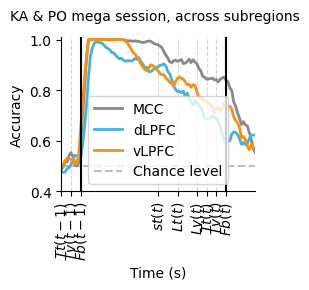

In [4]:
fig, ax = plt.subplots(figsize=(2.5, 2))

for subregion, data_projected in decodabilities.items():
    data = data_projected.decodability.values
    data = np.convolve(data, np.ones((5,))/5, mode='same')
    ax.plot(data_projected.time.values, data, label=subregion, color=COLORS[subregion], lw=2)


ax.axhline(y=0.5, color='grey', linestyle='--', alpha=0.5, label='Chance level')
    
plot_keypoints(ax, (-1, 0), mark_event='Fb', xlabels='events')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(alpha=0.5, linestyle='--', axis='x')
ax.set_xlim([-5, 5])
ax.set_ylim([0.4, 1.01])
ax.set_xlabel('Time (s)')
ax.set_ylabel('Accuracy', fontsize=10)
ax.legend()

# save figure
plt.suptitle(f'KA & PO mega session, across subregions', fontsize=10, y=1.02)
fig.savefig(os.path.join(FIGS_PATH, 'fig4a_feedback_decoding.svg'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [5]:
# Export source data (Figure 4a)
from popy.source_data import export_source_data

# curves as plotted above: decoding accuracy at each time point (mean over the 10 folds), 5-bin moving average,
# in the displayed time window (x-axis limits of the plot)
t_vec = decodabilities['MCC'].time.values
in_view = (t_vec >= -5 - 1e-6) & (t_vec <= 5 + 1e-6)
sd_4a = pd.DataFrame({'Time (s)': t_vec[in_view]})
for subregion_sd, data_projected_sd in decodabilities.items():
    assert np.array_equal(data_projected_sd.time.values, t_vec)
    accuracy_sd = np.convolve(data_projected_sd.decodability.values, np.ones((5,))/5, mode='same')
    sd_4a[f'{subregion_sd} decoding accuracy (fraction correct)'] = accuracy_sd[in_view]

n_units_sd = ', '.join(f'{s}: {n}' for s, n in zip(*np.unique(neural_dataset_all.subregion.values, return_counts=True)))
n_trials_sd = np.unique(neural_dataset_all.fb_sequence.values, return_counts=True)[1]
export_source_data(
    'Figure 4a',
    {'Decoding accuracy (lines)': sd_4a,
     'Chance level (dashed line)': pd.DataFrame({'Decoding accuracy (fraction correct)': [0.5]})},
    'Time course of the feedback decoding accuracy (fraction of correctly classified test trials, shown in % in the figure) in the '
    f'composite session of each region (units of all sessions of both monkeys pooled; {n_units_sd} units; {neural_dataset_all.sizes["trial_id"]} '
    f'trials, {n_trials_sd.min()} per history of the last three outcomes). A logistic regression decoder of the outcome of trial t '
    '(rewarded vs. unrewarded) is trained and tested at each time point (10-fold cross-validation, mean over folds), moving average '
    f'over 5 time bins ({5 * (t_vec[1] - t_vec[0]):.1f} s). Time: time-normalized trial time (s), Tt(t) = -5 s, Fb(t) = -4 s, Lt(t+1) = 1 s, '
    'Tt(t+1) = 2.5 s, Fb(t+1) = 3.5 s. Dashed line: chance level. No error bars.')

Figure 4a: source data saved (101 rows, 1 rows)


---
# Fig. 4b, Neural value

MCC
dLPFC
vLPFC


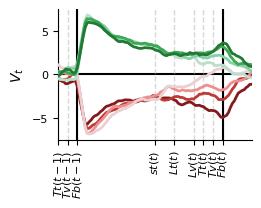

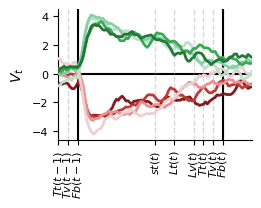

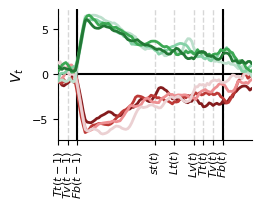

In [6]:
for subregion, data in decodabilities.items():    
    print(subregion)
    fig2, ax2 = plot_projected_data(data, t_interest_value=None, n_extra_trials=(-1, 0), paper_format=True, xlim=[-5, 5])

    # save as svgs
    fig2.savefig(os.path.join(FIGS_PATH, f'fig4b_{subregion}_neural_value.svg'), bbox_inches='tight', transparent=True)

In [7]:
# Export source data (Figure 4b)
from popy.source_data import export_source_data
from scipy import ndimage

# MCC (shown in the paper), same averaging and smoothing as in plot_projected_data(): mean projection of the trials of each
# history of the last three outcomes, moving average over 0.5 s, in the displayed time window
data_projected_sd = decodabilities['MCC']
t_vec = data_projected_sd.time.values
in_view = (t_vec >= -5 - 1e-6) & (t_vec <= 5 + 1e-6)
window_sd = np.ones(int(0.5 / (t_vec[1] - t_vec[0])))
window_sd = window_sd / len(window_sd)
sign_sd = {0: '-', 1: '+'}
sd_4b = pd.DataFrame({'Time (s)': t_vec[in_view]})
for fb_sequence_sd in np.sort(np.unique(data_projected_sd.fb_sequence.data)):
    # history code = 4 x outcome(t) + 2 x outcome(t-1) + outcome(t-2), 1: rewarded (legend: t-2, t-1, t)
    r_t, r_t1, r_t2 = int(fb_sequence_sd) // 4, (int(fb_sequence_sd) // 2) % 2, int(fb_sequence_sd) % 2
    class_mean_sd = np.mean(data_projected_sd.where(data_projected_sd.fb_sequence == fb_sequence_sd), axis=0)
    class_mean_sd = ndimage.convolve(class_mean_sd, window_sd, mode='nearest')
    sd_4b[f'Neural value, outcomes (t-2, t-1, t) = ({sign_sd[r_t2]}, {sign_sd[r_t1]}, {sign_sd[r_t]}) (arb. units)'] = class_mean_sd[in_view]

n_trials_sd = np.unique(data_projected_sd.fb_sequence.values, return_counts=True)[1]
export_source_data(
    'Figure 4b',
    sd_4b,
    'Population activity of the MCC composite session (units of all sessions of both monkeys pooled, '
    f'{int((neural_dataset_all.subregion.values == "MCC").sum())} units) '
    'projected onto the decision vector subspace (DVS) of the feedback decoder of Fig. 4a (decision value of the decoder trained at each time '
    'point, on the test trials of the 10-fold cross-validation; neural value, arbitrary units), averaged over the trials with the same '
    f'history of the last three outcomes (t-2, t-1, t; +: rewarded, -: unrewarded; {n_trials_sd.min()} trials per history), moving average '
    'over 0.5 s. Time axis as in Fig. 4a. No error bars.')

Figure 4b: source data saved (101 rows)
